**This version executes the machine learning analysis of the siver nanoparticles processing while uploading the cleaned file as well as processing it and giving the outputs depending on the applied model.** Version 1.0. Creators: Aura Ximena Gonzalez Cely

In [57]:
import pandas as pd
import re
import numpy as np
#Classification model libraries
from sklearn.svm import SVC
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import confusion_matrix, accuracy_score, precision_recall_fscore_support
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
#Regression model libraries
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV

#Evaluation libraries and plots
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt


In [33]:
# Read Excel file
df = pd.read_excel("/content/Raw data.xlsx")

df_selec = df.iloc[:, 1:10] #Rows of interest
df_selec = df_selec.iloc[:57, :] # Columns of interest

# Verify
print("selection: ", df_selec.head())
print(df_selec.info())


selection:           pH Temperature (°C) Stirring time (min) Concentration extract (%)  \
0   7,0-9,0               34                  60                      3.47   
1  4,0-10,0            25-80              20-120                      5-20   
2   5,0-9,0            25-75               30-90                      5-15   
3   6,0-8,0            25-70               30-90                         5   
4   6,5-7,5            40-70                  60                         5   

       Plant type         Nanoparticle shape Nanoparticle size (nm)  \
0  Mandarin waste                  Spherical                  15-35   
1  Various plants  Spherical and anisotropic                   5-50   
2  Various plants  Spherical and anisotropic                  10-50   
3        Hibiscus    Spherical or aggregates                  20-70   
4        Hibiscus                  Spherical                  30-60   

  Zeta potential (mV)     Properties  
0           -25 a -35        Removal  
1           -2

In [34]:
def separate_min_max(val):
    if pd.isna(val):
        return pd.Series([None, None])
    # Convert to string and replace comma per point
    val_str = str(val).replace(',', '.').strip()

    # Delete any character that is not a number, such as a point or a middle dash
    val_str = re.sub(r'[^0-9\.\-]', '', val_str)

    # Separate range of numbers whether there is a middle dash
    if '-' in val_str:
        parts = val_str.split('-')
        try:
            min_val = float(parts[0])
            max_val = float(parts[1])
        except ValueError:
            min_val = max_val = None
    else:
        try:
            min_val = max_val = float(val_str)
        except ValueError:
            min_val = max_val = None

    return pd.Series([min_val, max_val])

# Aplicar la función
column_pH = df_selec.iloc[:, 0] # pH
df_selec[['pH_min', 'pH_max']] = column_pH.apply(separate_min_max)

column_temp = df_selec.iloc[:, 1]  # temperature
df_selec[['temp_min', 'temp_max']] = column_temp.apply(separate_min_max)

column_stirr = df_selec.iloc[:, 2]  # stirring time
df_selec[['stirrtime_min', 'stirrtime_max']] = column_stirr.apply(separate_min_max)

column_extrac = df_selec.iloc[:, 3]  # extracto
df_selec[['extract_min', 'extract_max']] = column_extrac.apply(separate_min_max)

column_nanosize = df_selec.iloc[:, 6]  # tamano nanoparticula
df_selec[['nanosize_min', 'nanosize_max']] = column_nanosize.apply(separate_min_max)


In [35]:
def separate_range(val):
    if pd.isna(val):
        return pd.Series([None, None])

    val_str = str(val).replace(',', '.').strip()

    # Look for the numbers, even if it's a negative value
    match = re.match(r'(-?\d+\.?\d*)\s*(?:-|a)\s*(-?\d+\.?\d*)', val_str)

    if match:
        min_val = float(match.group(1))
        max_val = float(match.group(2))
    else:
        try:
            min_val = max_val = float(val_str)
        except ValueError:
            min_val = max_val = None

    return pd.Series([min_val, max_val])

# Apply function

column_zetapot = df_selec.iloc[:, 7]  # zeta potential
df_selec[['zetapot_min', 'zetapot_max']] = column_zetapot.apply(separate_range)




In [36]:

map_names = {
    "Antimicrobial": 1,
    "Antioxidant": 2,
    "Synthesis": 3,
    "Antibacterial": 4
}

# Select and map values of the nanoparticle shape
df_selec["Property"] = df_selec.iloc[:, 8].map(map_names)

counting_names = df_selec.iloc[:, 8].value_counts()
print("counting names: ", counting_names)
print(df_selec)

counting names:  Properties
Antimicrobial                        21
Synthesis                            15
Antibacterial                         7
Antioxidant                           4
Inhibition                            1
Removal                               1
Green applications                    1
Farmacology                           1
Environmental sensor                  1
Healing                               1
Biological activity                   1
Degradation                           1
Nanonutrient effect                   1
Optical and biological properties     1
Name: count, dtype: int64
          pH Temperature (°C) Stirring time (min) Concentration extract (%)  \
0    7,0-9,0               34                  60                      3.47   
1   4,0-10,0            25-80              20-120                      5-20   
2    5,0-9,0            25-75               30-90                      5-15   
3    6,0-8,0            25-70               30-90                     

Labels para la forma de la nanoparticula
1=Esférica, 2=Esférica y anisotrópica, 3=Esférica o aglomerados, 4=Anisotrópica, 5=Esférica o anisotrópica

In [37]:
map_shape = {
    "Spherical": 1,
    "Spherical and anisotropic": 2,
    "Spherical or aggregates": 3,
    "Anisotropic": 4,
    "Spherical or anisotropic": 5,
    "Spherical and poligonal" : 6
}

# Select map shape from column [:,5]
df_selec["Shape"] = df_selec.iloc[:, 5].map(map_shape)

counting_names = df_selec.iloc[:, 5].value_counts()
print("counting_names: ", counting_names)
print(df_selec.head())

counting_names:  Nanoparticle shape
Spherical                    42
Spherical and anisotropic     4
Spherical and poligonal       4
Spherical or aggregates       2
Anisotropic                   2
Spherical or anisotropic      2
Spherical or anisotrophic     1
Name: count, dtype: int64
         pH Temperature (°C) Stirring time (min) Concentration extract (%)  \
0   7,0-9,0               34                  60                      3.47   
1  4,0-10,0            25-80              20-120                      5-20   
2   5,0-9,0            25-75               30-90                      5-15   
3   6,0-8,0            25-70               30-90                         5   
4   6,5-7,5            40-70                  60                         5   

       Plant type         Nanoparticle shape Nanoparticle size (nm)  \
0  Mandarin waste                  Spherical                  15-35   
1  Various plants  Spherical and anisotropic                   5-50   
2  Various plants  Spherical and

In [38]:
map_type = {
    'Mandarin waste': 1,
    'Various plants': 2,
    'Hibiscus': 3,
    'Caralluma subulata': 4,
    'Tobaco': 5,
    'Fruit': 6,
    'Dioscorea bulbifera': 7,
    'Piper longum catkin': 8,
    'Lawsonia inermis': 9,
    'Capparis zeylanica': 10,
    'Medicinal plants': 11,
    'Sansevieria trifasciata': 12,
    'Biopolimers': 13,
    'Carambola': 14,
    'Camellia': 15,
    'Mangifera leaves': 16,
    'Vernoria leaves': 17,
    'Onion peel': 18,
    'Biosurfuctant': 19,
    'Solanum leaves': 20,
    'Cacao leaves': 21,
    'Moringa leaves': 22,
    'Azadirachta': 23,
    'Persea leaves': 24,
    'Croton roots': 25,
    'Coleus root': 26,
    'Lemon leaves': 27,
    'Banana peel': 28,
    'Tectona seeds': 29,
    'Olive leaves': 30,
    'Acalyoha leaves': 31,
    'Ficus benghalensis leaves': 32,
    'Litchi leaves': 33,
    'Salvia leaves': 34,
    'Orange waste': 35
}

df_selec["Plant types"] = df_selec.iloc[:, 4].map(map_type)
counting_names = df_selec.iloc[:, 4].value_counts(dropna=False)

print("counting_names:", counting_names)
print(df_selec.head())

counting_names: Plant type
Various plants                  15
Hibiscus                         3
Sansevieria trifasciata          3
Caralluma subulata               2
Lemon leaves                     2
Non specified                    2
Mandarin waste                   1
Fruit                            1
Piper longum catkin              1
Lawsonia inermis                 1
Capparis zeylanica               1
Tobaco                           1
Plantas medicinales variadas     1
Biopolimeros                     1
Carambola                        1
Camellia                         1
Mangifera leaves                 1
Vernoria leaves                  1
Onion peel                       1
Dioscorea bulbifera              1
Biosurfactante                   1
Solanum leaves                   1
Moringa leaves                   1
Cacao leaves                     1
Azadirachta                      1
Persea leaves                    1
Croton roots                     1
Coleus root                 

In [41]:
df_sub = df_selec.iloc[:, 9:24]

# Verify info
print(df_sub.head())
print(df_sub.shape)

# Normalization column by column
df_norm = df_sub.copy()

for col in df_norm.columns:
    col_mean = df_norm[col].mean(skipna=True)
    col_std = df_norm[col].std(skipna=True)
    df_norm[col] = (df_norm[col] - col_mean) / col_std

# Verify normalization
print("Normalized df: ",df_norm.head())

# DataFrame with rows that have at least one NaN value
df_nan = df_norm[df_norm.isna().any(axis=1)]

# DataFrame with rows without NaN values
df_no_nan = df_norm[df_norm.notna().all(axis=1)]
print(df_nan.shape, df_no_nan.shape)
print(df_no_nan.head())


   pH_min  pH_max  temp_min  temp_max  stirrtime_min  stirrtime_max  \
0     7.0     9.0      34.0      34.0           60.0           60.0   
1     4.0    10.0      25.0      80.0           20.0          120.0   
2     5.0     9.0      25.0      75.0           30.0           90.0   
3     6.0     8.0      25.0      70.0           30.0           90.0   
4     6.5     7.5      40.0      70.0           60.0           60.0   

   extract_min  extract_max  nanosize_min  nanosize_max  zetapot_min  \
0         3.47         3.47          15.0          35.0        -25.0   
1         5.00        20.00           5.0          50.0        -20.0   
2         5.00        15.00          10.0          50.0        -20.0   
3         5.00         5.00          20.0          70.0        -25.0   
4         5.00         5.00          30.0          60.0        -30.0   

   zetapot_max  Property  Shape  Plant types  
0        -35.0       NaN    1.0          1.0  
1        -40.0       1.0    2.0          2.0  

In [42]:
# Define target
target_col = "Property"

# Categorical class definition
Y = pd.Categorical(df_no_nan[target_col]).codes

# Delete target from the dataframe
X = df_no_nan.drop(columns=[target_col])

# Data replication to avoid unbalanced data
df_balanced = df_no_nan.copy()
df_balanced["Y"] = Y

classes = np.unique(Y)
maxCount = df_balanced["Y"].value_counts().max()

data_balanced = df_balanced.copy()

for c in classes:

    rows_class = df_balanced[df_balanced["Y"] == c]

    nRep = maxCount - len(rows_class)

    if nRep > 0:
        rows_add = rows_class.sample(n=nRep, replace=True, random_state=42)
        data_balanced = pd.concat([data_balanced, rows_add], ignore_index=True)

# Define final data and target
Y_bal = data_balanced["Y"].values
X_bal = data_balanced.drop(columns=[target_col, "Y"]).values

# Apply LeaveOneOut for validation
loo = LeaveOneOut()
predicciones = np.zeros(len(Y_bal))

for train_idx, test_idx in loo.split(X_bal):


    model = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=10, gamma="scale")
    ) #Model with data normalization

    model.fit(X_bal[train_idx], Y_bal[train_idx])

    predicciones[test_idx] = model.predict(X_bal[test_idx])


accuracy = accuracy_score(Y_bal, predicciones)
C = confusion_matrix(Y_bal, predicciones)
precision, recall, f1, _ = precision_recall_fscore_support(
    Y_bal,
    predicciones,
    average=None,
    zero_division=0
)

print(f"Accuracy LOOCV: {accuracy * 100:.2f}%")
print("\nConfusion Matrix:\n", C)
print("\nResults per class:\n")
for i in range(len(precision)):
    print(
        f"Class {i}: Precision={precision[i]:.2f}, "
        f"Recall={recall[i]:.2f}, F1={f1[i]:.2f}"
    )


print("Average Precision:", precision.mean())
print("Average Recall:", recall.mean())
print("Average F1:", f1.mean())

Accuracy LOOCV: 91.18%

Confusion Matrix:
 [[12  0  2  3]
 [ 0 17  0  0]
 [ 0  1 16  0]
 [ 0  0  0 17]]

Results per class:

Class 0: Precision=1.00, Recall=0.71, F1=0.83
Class 1: Precision=0.94, Recall=1.00, F1=0.97
Class 2: Precision=0.89, Recall=0.94, F1=0.91
Class 3: Precision=0.85, Recall=1.00, F1=0.92
Average Precision: 0.9208333333333333
Average Recall: 0.911764705882353
Average F1: 0.908054852882439


**Regressor models code**

In [44]:
# Linear Regressor nanosize min y nanosize max
df = df_no_nan

# Separating features and labels
y = df.iloc[:, [-6, -5]].values
feature_cols = [i for i in range(df.shape[1]) if i not in [df.shape[1]-6, df.shape[1]-5]]
X = df.iloc[:, feature_cols].values

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

# Applying LeaveOneOut validation
loo = LeaveOneOut()
model = LinearRegression()
errors = []

for train_idx, test_idx in loo.split(X):  # Separating training and test data
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    model.fit(X_train, y_train)   #Training the model
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    errors.append(mse)

# Average RMSE
rmse = np.sqrt(np.mean(errors))
print(f"Average RMSE (Leave-One-Out): {rmse:.4f}")


Feature shape: (33, 13)
Target shape: (33, 2)
Average RMSE (Leave-One-Out): 0.8817


In [52]:
# Random Forest Regressor with hyperparameters selection

df = df_no_nan

# Targets
y = df.iloc[:, [-6, -5]].values

# Features
feature_cols = [i for i in range(df.shape[1])
                if i not in [df.shape[1]-6, df.shape[1]-5]]

X = df.iloc[:, feature_cols].values

# Leave-One-Out cross-validation
loo = LeaveOneOut()

# Hyperparameters to test
n_estimators_list = [100, 200]
max_depth_list = [None, 5, 10, 20]
min_samples_split_list = [2, 5, 10]

# Store results
results = []

for n_estimators in n_estimators_list:

    for max_depth in max_depth_list:

        for min_samples_split in min_samples_split_list:

            errors_per_target = []

            print(f"Testing n_estimators: ", n_estimators)
            print(f"max_depth: ", max_depth)

            # Leave-One-Out loop
            for train_idx, test_idx in loo.split(X):

                # Split data
                X_train, X_test = X[train_idx], X[test_idx]
                y_train, y_test = y[train_idx], y[test_idx]

                # Predictions container
                y_pred = np.zeros_like(y_test, dtype=float)

                # Train one RF per target
                for i in range(y.shape[1]):

                    rf = RandomForestRegressor(
                        n_estimators=n_estimators,
                        max_depth=max_depth,
                        min_samples_split=min_samples_split,
                        random_state=42,
                        n_jobs=-1
                    )

                    rf.fit(X_train, y_train[:, i])

                    y_pred[:, i] = rf.predict(X_test)

                # Squared error
                errors_per_target.append((y_test - y_pred) ** 2)

            errors_per_target = np.array(errors_per_target)

            rmse_per_target = np.sqrt(
                np.mean(errors_per_target, axis=0)
            ).flatten()

            rmse_average = np.mean(rmse_per_target)

            # Save result
            results.append({
                "n_estimators": n_estimators,
                "max_depth": max_depth,
                "min_samples_split": min_samples_split,
                "rmse_target_1": rmse_per_target[0],
                "rmse_target_2": rmse_per_target[1],
                "rmse_average": rmse_average
            })

best_result = min(results, key=lambda x: x["rmse_average"])

print(f"best n_estimators : {best_result['n_estimators']}")
print(f"best max_depth    : {best_result['max_depth']}")
print(f"best min_samples_split : {best_result['min_samples_split']}")

print(f"RMSE target 1: {best_result['rmse_target_1']:.4f}")
print(f"RMSE target 2: {best_result['rmse_target_2']:.4f}")
print(f"Average RMSE : {best_result['rmse_average']:.4f}")

Testing n_estimators:  100
max_depth:  None
Testing n_estimators:  100
max_depth:  None
Testing n_estimators:  100
max_depth:  None
Testing n_estimators:  100
max_depth:  5
Testing n_estimators:  100
max_depth:  5
Testing n_estimators:  100
max_depth:  5
Testing n_estimators:  100
max_depth:  10
Testing n_estimators:  100
max_depth:  10
Testing n_estimators:  100
max_depth:  10
Testing n_estimators:  100
max_depth:  20
Testing n_estimators:  100
max_depth:  20
Testing n_estimators:  100
max_depth:  20
Testing n_estimators:  200
max_depth:  None
Testing n_estimators:  200
max_depth:  None
Testing n_estimators:  200
max_depth:  None
Testing n_estimators:  200
max_depth:  5
Testing n_estimators:  200
max_depth:  5
Testing n_estimators:  200
max_depth:  5
Testing n_estimators:  200
max_depth:  10
Testing n_estimators:  200
max_depth:  10
Testing n_estimators:  200
max_depth:  10
Testing n_estimators:  200
max_depth:  20
Testing n_estimators:  200
max_depth:  20
Testing n_estimators:  200
m

In [54]:
df = df_no_nan

# Split dataset for features and output feature
y = df.iloc[:, [-6, -5]].values
feature_cols = [i for i in range(df.shape[1]) if i not in [df.shape[1]-6, df.shape[1]-5]]
X = df.iloc[:, feature_cols].values

Optimized RandomForest RMSE:
  Min: 0.9498
  Max: 0.5566
  Mean: 0.7532


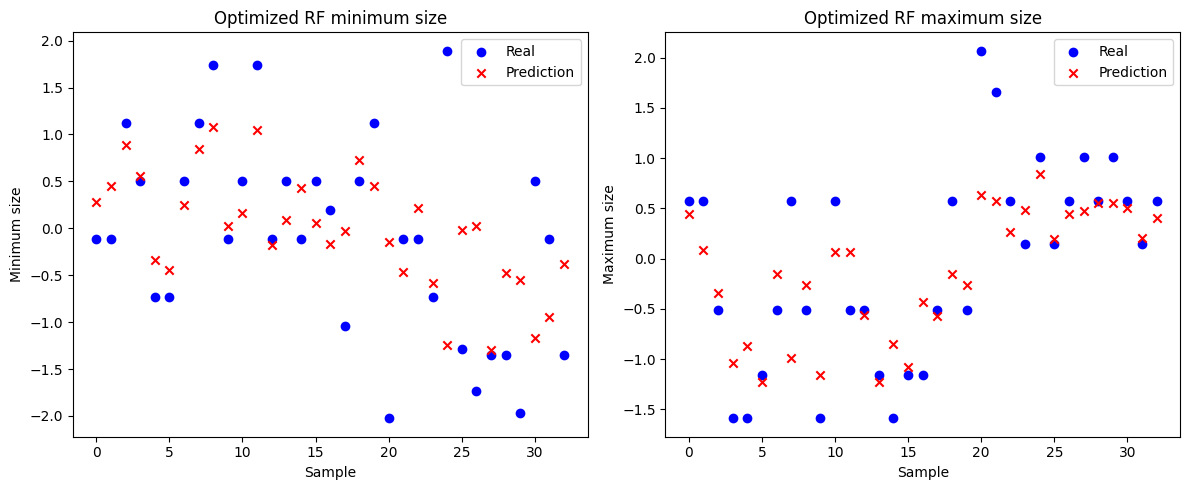

In [53]:
#Training RF model considering the best hyperparameter from the previous code

# Best hyperparameters previously found
best_params = {
    'mínimo': {'n_estimators': 200, 'max_depth': 5, 'min_samples_split': 2},
    'máximo': {'n_estimators': 200, 'max_depth': 5, 'min_samples_split': 2}
}

# LeaveOneOut
loo = LeaveOneOut()
y_true_min, y_true_max = [], []
y_pred_min, y_pred_max = [], []

for train_idx, test_idx in loo.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    rf_min = RandomForestRegressor(random_state=42, **best_params['mínimo'])
    rf_max = RandomForestRegressor(random_state=42, **best_params['máximo'])

    rf_min.fit(X_train, y_train[:, 0])
    rf_max.fit(X_train, y_train[:, 1])

    y_pred_min.append(rf_min.predict(X_test)[0])
    y_pred_max.append(rf_max.predict(X_test)[0])
    y_true_min.append(y_test[0, 0])
    y_true_max.append(y_test[0, 1])

rmse_min = np.sqrt(mean_squared_error(y_true_min, y_pred_min))
rmse_max = np.sqrt(mean_squared_error(y_true_max, y_pred_max))
rmse_avg = np.mean([rmse_min, rmse_max])

print(f"Optimized RandomForest RMSE:")
print(f"  Min: {rmse_min:.4f}")
print(f"  Max: {rmse_max:.4f}")
print(f"  Mean: {rmse_avg:.4f}")

# Scatter Plot
plt.figure(figsize=(12,5))

# Minimum size
plt.subplot(1,2,1)
plt.scatter(range(len(y_true_min)), y_true_min, color='blue', label='Real')
plt.scatter(range(len(y_pred_min)), y_pred_min, color='red', marker='x', label='Prediction')
plt.xlabel('Sample')
plt.ylabel('Minimum size')
plt.title('Optimized RF minimum size')
plt.legend()

# Max size
plt.subplot(1,2,2)
plt.scatter(range(len(y_true_max)), y_true_max, color='blue', label='Real')
plt.scatter(range(len(y_pred_max)), y_pred_max, color='red', marker='x', label='Prediction')
plt.xlabel('Sample')
plt.ylabel('Maximum size')
plt.title('Optimized RF maximum size')
plt.legend()

plt.tight_layout()
plt.show()



In [55]:
# Gradient Boost hyperparameter selection
loo = LeaveOneOut()

# Hyperparameters
n_estimators_list = [100, 200]
max_depth_list = [2, 3, 4]
min_samples_leaf_list = [1, 2, 4]
learning_rate_list = [0.05, 0.1, 0.2]

results = []

for n_estimators in n_estimators_list:
    for max_depth in max_depth_list:
        for min_samples_leaf in min_samples_leaf_list:
            for learning_rate in learning_rate_list:

                y_pred_min = []
                y_pred_max = []
                y_true_min = []
                y_true_max = []

                for train_idx, test_idx in loo.split(X):
                    X_train, X_test = X[train_idx], X[test_idx]
                    y_train, y_test = y[train_idx], y[test_idx]

                    gbr_min = GradientBoostingRegressor(
                        n_estimators=n_estimators,
                        learning_rate=learning_rate,
                        max_depth=max_depth,
                        min_samples_leaf=min_samples_leaf,
                        random_state=42
                    )

                    gbr_max = GradientBoostingRegressor(
                        n_estimators=n_estimators,
                        learning_rate=learning_rate,
                        max_depth=max_depth,
                        min_samples_leaf=min_samples_leaf,
                        random_state=42
                    )

                    gbr_min.fit(X_train, y_train[:, 0])
                    gbr_max.fit(X_train, y_train[:, 1])

                    y_pred_min.append(gbr_min.predict(X_test)[0])
                    y_pred_max.append(gbr_max.predict(X_test)[0])
                    y_true_min.append(y_test[0, 0])
                    y_true_max.append(y_test[0, 1])

                rmse_min = np.sqrt(mean_squared_error(y_true_min, y_pred_min))
                rmse_max = np.sqrt(mean_squared_error(y_true_max, y_pred_max))
                rmse_avg = np.mean([rmse_min, rmse_max])

                results.append({
                    "n_estimators": n_estimators,
                    "max_depth": max_depth,
                    "min_samples_leaf": min_samples_leaf,
                    "learning_rate": learning_rate,
                    "rmse_min": rmse_min,
                    "rmse_max": rmse_max,
                    "rmse_avg": rmse_avg
                })

                print(
                    f"n_estimators={n_estimators}, "
                    f"max_depth={max_depth}, "
                    f"min_samples_leaf={min_samples_leaf}, "
                    f"learning_rate={learning_rate}, "
                    f"RMSE avg={rmse_avg:.4f}"
                )

best_result = min(results, key=lambda x: x["rmse_avg"])

print(f"Best n_estimators: {best_result['n_estimators']}")
print(f"Best max_depth: {best_result['max_depth']}")
print(f"Best min_samples_leaf: {best_result['min_samples_leaf']}")
print(f"learning_rate: {best_result['learning_rate']}")
print(f"RMSE min: {best_result['rmse_min']:.4f}")
print(f"RMSE max: {best_result['rmse_max']:.4f}")
print(f"RMSE avg: {best_result['rmse_avg']:.4f}")

n_estimators=100, max_depth=2, min_samples_leaf=1, learning_rate=0.05, RMSE avg=0.7809
n_estimators=100, max_depth=2, min_samples_leaf=1, learning_rate=0.1, RMSE avg=0.7692
n_estimators=100, max_depth=2, min_samples_leaf=1, learning_rate=0.2, RMSE avg=0.8149
n_estimators=100, max_depth=2, min_samples_leaf=2, learning_rate=0.05, RMSE avg=0.8224
n_estimators=100, max_depth=2, min_samples_leaf=2, learning_rate=0.1, RMSE avg=0.8465
n_estimators=100, max_depth=2, min_samples_leaf=2, learning_rate=0.2, RMSE avg=0.8745
n_estimators=100, max_depth=2, min_samples_leaf=4, learning_rate=0.05, RMSE avg=0.8236
n_estimators=100, max_depth=2, min_samples_leaf=4, learning_rate=0.1, RMSE avg=0.8512
n_estimators=100, max_depth=2, min_samples_leaf=4, learning_rate=0.2, RMSE avg=0.8814
n_estimators=100, max_depth=3, min_samples_leaf=1, learning_rate=0.05, RMSE avg=0.7474
n_estimators=100, max_depth=3, min_samples_leaf=1, learning_rate=0.1, RMSE avg=0.7402
n_estimators=100, max_depth=3, min_samples_leaf=1,

In [56]:
# Gradient Boost Regressor for nanosize min y nanosize max using best hyperparameters

loo = LeaveOneOut()
errors = []

y_pred_min = []
y_pred_max = []
y_true_min = []
y_true_max = []

for train_idx, test_idx in loo.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # GradientBoosting per target
    gbr_min = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, min_samples_leaf=1, max_depth=3, random_state=42)
    gbr_max = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, min_samples_leaf=1, max_depth=3, random_state=42)

    gbr_min.fit(X_train, y_train[:, 0])
    gbr_max.fit(X_train, y_train[:, 1])

    y_pred_min.append(gbr_min.predict(X_test)[0])
    y_pred_max.append(gbr_max.predict(X_test)[0])
    y_true_min.append(y_test[0, 0])
    y_true_max.append(y_test[0, 1])

# RMSE per target
rmse_min = np.sqrt(mean_squared_error(y_true_min, y_pred_min))
rmse_max = np.sqrt(mean_squared_error(y_true_max, y_pred_max))
rmse_avg = np.mean([rmse_min, rmse_max])

print(f"GradientBoosting RMSE: min={rmse_min:.4f}, max={rmse_max:.4f}, average={rmse_avg:.4f}")


GradientBoosting RMSE: min=0.9495, max=0.5300, average=0.7398


K= 2, RMSE_min=0.8519, RMSE_max=0.9094, RMSE_avg=0.8807
K= 3, RMSE_min=0.8236, RMSE_max=0.8491, RMSE_avg=0.8364
K= 4, RMSE_min=0.8547, RMSE_max=0.7637, RMSE_avg=0.8092
K= 5, RMSE_min=0.8701, RMSE_max=0.7999, RMSE_avg=0.8350
K= 6, RMSE_min=0.9105, RMSE_max=0.7831, RMSE_avg=0.8468
K= 7, RMSE_min=0.9285, RMSE_max=0.8223, RMSE_avg=0.8754
K= 8, RMSE_min=0.9218, RMSE_max=0.7959, RMSE_avg=0.8589
K= 9, RMSE_min=0.9197, RMSE_max=0.8060, RMSE_avg=0.8629
K=10, RMSE_min=0.9095, RMSE_max=0.8348, RMSE_avg=0.8722
K=11, RMSE_min=0.9326, RMSE_max=0.8362, RMSE_avg=0.8844
K=12, RMSE_min=0.9629, RMSE_max=0.8496, RMSE_avg=0.9063
K=13, RMSE_min=0.9538, RMSE_max=0.8668, RMSE_avg=0.9103
K=14, RMSE_min=0.9527, RMSE_max=0.8805, RMSE_avg=0.9166
K=15, RMSE_min=0.9475, RMSE_max=0.8920, RMSE_avg=0.9197
Best k value found: k           4.000000
RMSE_min    0.854683
RMSE_max    0.763738
RMSE_avg    0.809210
Name: 2, dtype: float64


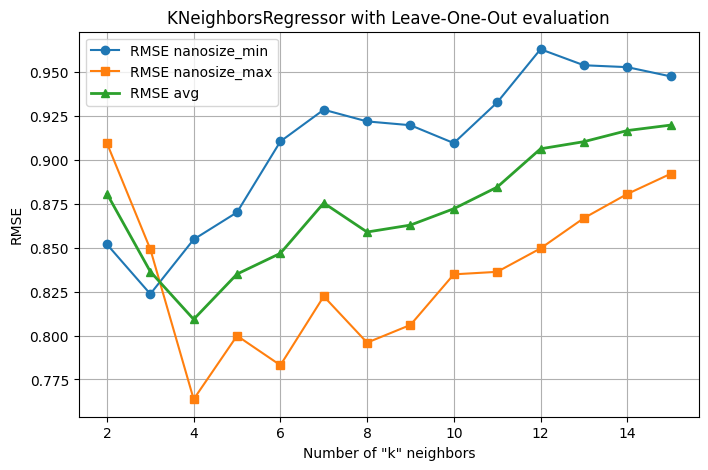

In [58]:
# k nearest neighbors hyperparameter selection
df = df_no_nan

# Split features
y = df.iloc[:, [-6, -5]].values  # nanosize_min y nanosize_max
feature_cols = [i for i in range(df.shape[1]) if i not in [df.shape[1]-6, df.shape[1]-5]]
X = df.iloc[:, feature_cols].values

# Hyperparameter selection "k"
k_values = range(2, 16)
rmse_results = []

loo = LeaveOneOut()

for k in k_values:
    model_min = KNeighborsRegressor(n_neighbors=k, weights='distance')
    model_max = KNeighborsRegressor(n_neighbors=k, weights='distance')

    y_true_min, y_pred_min = [], []
    y_true_max, y_pred_max = [], []

    for train_idx, test_idx in loo.split(X):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        # Train both models per output feature
        model_min.fit(X_train, y_train[:, 0])
        model_max.fit(X_train, y_train[:, 1])

        y_pred_min.append(model_min.predict(X_test)[0])
        y_pred_max.append(model_max.predict(X_test)[0])
        y_true_min.append(y_test[0, 0])
        y_true_max.append(y_test[0, 1])

    # RMSE per target
    rmse_min = np.sqrt(mean_squared_error(y_true_min, y_pred_min))
    rmse_max = np.sqrt(mean_squared_error(y_true_max, y_pred_max))
    rmse_avg = np.mean([rmse_min, rmse_max])

    rmse_results.append((k, rmse_min, rmse_max, rmse_avg))
    print(f"K={k:2d}, RMSE_min={rmse_min:.4f}, RMSE_max={rmse_max:.4f}, RMSE_avg={rmse_avg:.4f}")


results_df = pd.DataFrame(rmse_results, columns=['k', 'RMSE_min', 'RMSE_max', 'RMSE_avg'])

# Best "k"
best_row = results_df.loc[results_df['RMSE_avg'].idxmin()]
print("Best k value found:", best_row)

# Plot
plt.figure(figsize=(8,5))
plt.plot(results_df['k'], results_df['RMSE_min'], 'o-', label='RMSE nanosize_min')
plt.plot(results_df['k'], results_df['RMSE_max'], 's-', label='RMSE nanosize_max')
plt.plot(results_df['k'], results_df['RMSE_avg'], '^-', label='RMSE avg', linewidth=2)
plt.xlabel('Number of "k" neighbors')
plt.ylabel('RMSE')
plt.title('KNeighborsRegressor with Leave-One-Out evaluation')
plt.legend()
plt.grid(True)
plt.show()


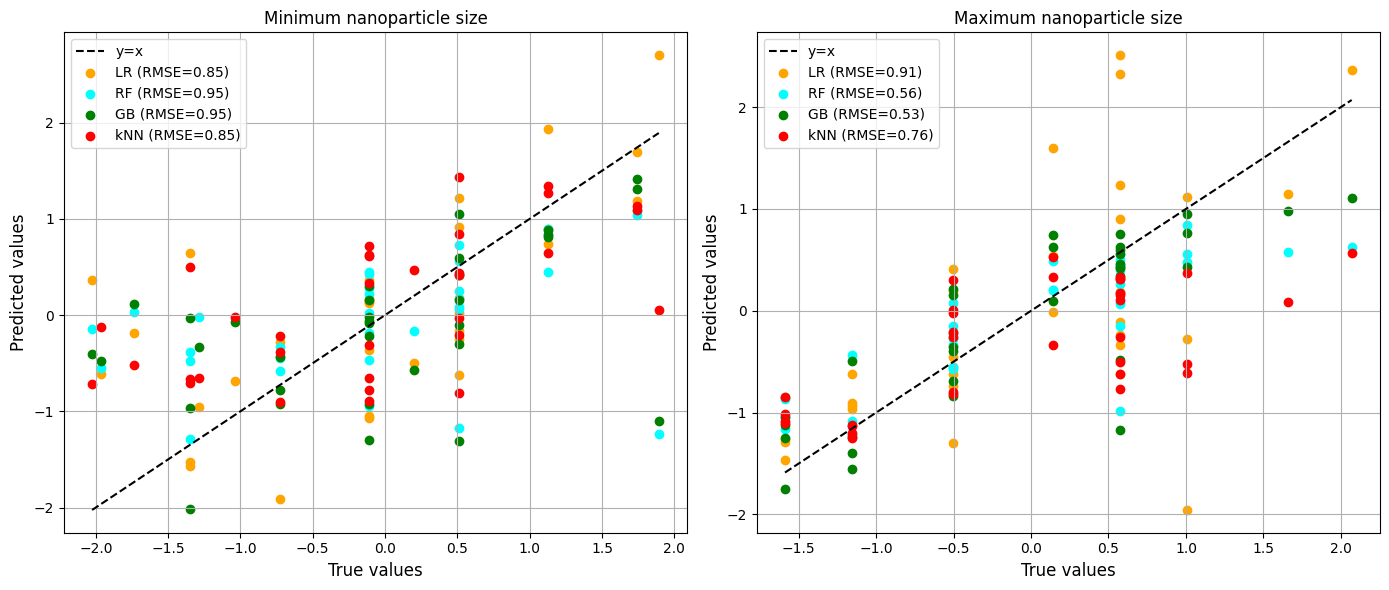

In [68]:
# Comparison all models with the best hyperparameter selection

# Initial values
X = df.iloc[:, [i for i in range(df.shape[1]) if i not in [df.shape[1]-6, df.shape[1]-5]]].values
y = df.iloc[:, [-6, -5]].values

loo = LeaveOneOut()

y_true_min, y_true_max = [], []

y_pred_lr = {'min': [], 'max': []}
y_pred_rf_default = {'min': [], 'max': []}
y_pred_rf_opt = {'min': [], 'max': []}
y_pred_gb = {'min': [], 'max': []}
y_pred_knn = {'min': [], 'max': []}

# Use of best "k" value previously found
best_k = 4
knn_min_model = KNeighborsRegressor(n_neighbors=best_k, weights='distance')
knn_max_model = KNeighborsRegressor(n_neighbors=best_k, weights='distance')

# Leave-One-Out
for train_idx, test_idx in loo.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    y_true_min.append(y_test[0, 0])
    y_true_max.append(y_test[0, 1])

    # Linear Regression
    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)
    y_pred_lr['min'].append(lr_model.predict(X_test)[0, 0])
    y_pred_lr['max'].append(lr_model.predict(X_test)[0, 1])

    # RandomForest
    rf_opt_min = RandomForestRegressor(n_estimators=200, max_depth=5, min_samples_split=2, random_state=42)
    rf_opt_max = RandomForestRegressor(n_estimators=200, max_depth=5, min_samples_split=2, random_state=42)
    rf_opt_min.fit(X_train, y_train[:, 0])
    rf_opt_max.fit(X_train, y_train[:, 1])
    y_pred_rf_opt['min'].append(rf_opt_min.predict(X_test)[0])
    y_pred_rf_opt['max'].append(rf_opt_max.predict(X_test)[0])

    # GradientBoosting
    gb_min = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, min_samples_leaf=1, max_depth=3, random_state=42)
    gb_max = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, min_samples_leaf=1, max_depth=3, random_state=42)
    gb_min.fit(X_train, y_train[:, 0])
    gb_max.fit(X_train, y_train[:, 1])
    y_pred_gb['min'].append(gb_min.predict(X_test)[0])
    y_pred_gb['max'].append(gb_max.predict(X_test)[0])

    # KNN
    knn_min_model.fit(X_train, y_train[:, 0])
    knn_max_model.fit(X_train, y_train[:, 1])
    y_pred_knn['min'].append(knn_min_model.predict(X_test)[0])
    y_pred_knn['max'].append(knn_max_model.predict(X_test)[0])

# Array conversion
y_true_min = np.array(y_true_min)
y_true_max = np.array(y_true_max)
for d in [y_pred_lr, y_pred_rf_default, y_pred_rf_opt, y_pred_gb, y_pred_knn]:
    d['min'] = np.array(d['min'])
    d['max'] = np.array(d['max'])

# RMSE calculation
rmse_lr_min = np.sqrt(mean_squared_error(y_true_min, y_pred_lr['min']))
rmse_lr_max = np.sqrt(mean_squared_error(y_true_max, y_pred_lr['max']))
rmse_rf_opt_min = np.sqrt(mean_squared_error(y_true_min, y_pred_rf_opt['min']))
rmse_rf_opt_max = np.sqrt(mean_squared_error(y_true_max, y_pred_rf_opt['max']))
rmse_gb_min = np.sqrt(mean_squared_error(y_true_min, y_pred_gb['min']))
rmse_gb_max = np.sqrt(mean_squared_error(y_true_max, y_pred_gb['max']))
rmse_knn_min = np.sqrt(mean_squared_error(y_true_min, y_pred_knn['min']))
rmse_knn_max = np.sqrt(mean_squared_error(y_true_max, y_pred_knn['max']))

# Plot
plt.figure(figsize=(14,6))

# nanosize_min
plt.subplot(1,2,1)
plt.plot([y_true_min.min(), y_true_min.max()], [y_true_min.min(), y_true_min.max()], 'k--', label='y=x')
plt.scatter(y_true_min, y_pred_lr['min'], color='orange', label=f'LR (RMSE={rmse_lr_min:.2f})')
plt.scatter(y_true_min, y_pred_rf_opt['min'], color='cyan', label=f'RF (RMSE={rmse_rf_opt_min:.2f})')
plt.scatter(y_true_min, y_pred_gb['min'], color='green', label=f'GB (RMSE={rmse_gb_min:.2f})')
plt.scatter(y_true_min, y_pred_knn['min'], color='red', label=f'kNN (RMSE={rmse_knn_min:.2f})')
plt.xlabel('True values', fontname='Calibri', fontsize=12)
plt.ylabel('Predicted values', fontname='Calibri', fontsize=12)
plt.title('Minimum nanoparticle size', fontname='Calibri', fontsize=12)
plt.legend()
plt.grid(True)

# nanosize_max
plt.subplot(1,2,2)
plt.plot([y_true_max.min(), y_true_max.max()], [y_true_max.min(), y_true_max.max()], 'k--', label='y=x')
plt.scatter(y_true_max, y_pred_lr['max'], color='orange', label=f'LR (RMSE={rmse_lr_max:.2f})')
plt.scatter(y_true_max, y_pred_rf_opt['max'], color='cyan', label=f'RF (RMSE={rmse_rf_opt_max:.2f})')
plt.scatter(y_true_max, y_pred_gb['max'], color='green', label=f'GB (RMSE={rmse_gb_max:.2f})')
plt.scatter(y_true_max, y_pred_knn['max'], color='red', label=f'kNN (RMSE={rmse_knn_max:.2f})')
plt.xlabel('True values', fontname='Calibri', fontsize=12)
plt.ylabel('Predicted values', fontname='Calibri', fontsize=12)
plt.title('Maximum nanoparticle size', fontname='Calibri', fontsize=12)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("CurveModels.eps", format='eps', dpi=300)
plt.show()


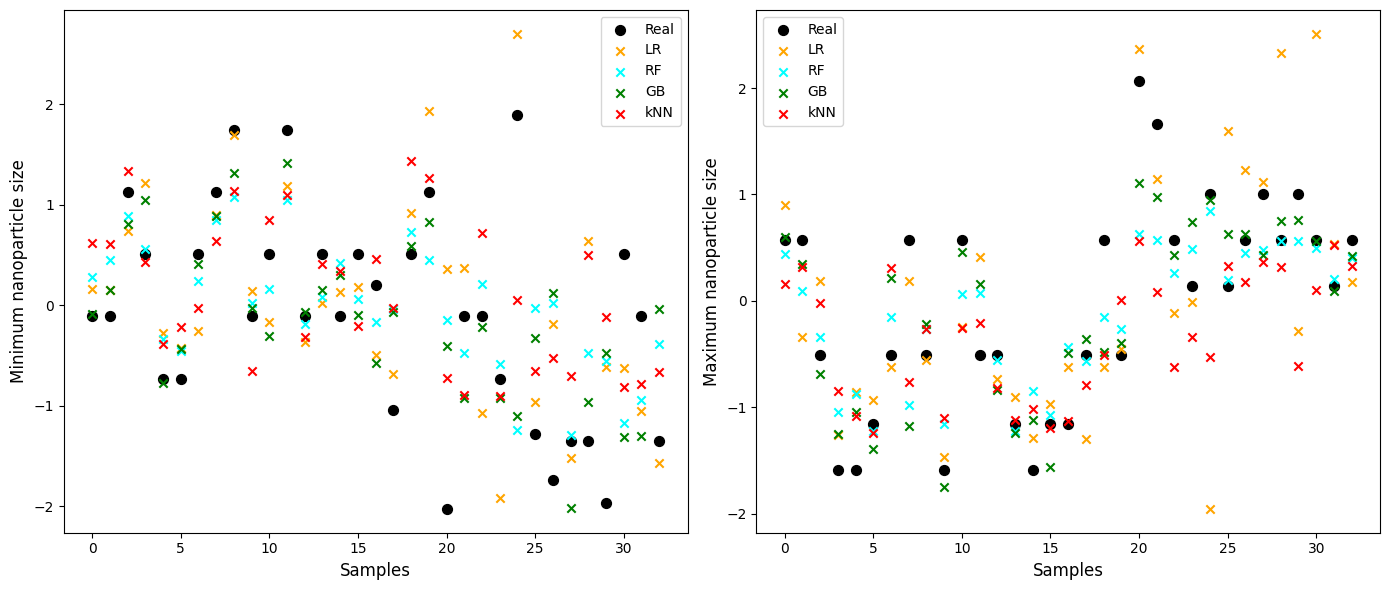

In [67]:
# Comparison real and predicted values per model using best hyperparameter selection

y_true_min, y_true_max = [], []

# Predictions per model
y_pred_lr = {'min': [], 'max': []}
y_pred_rf_default = {'min': [], 'max': []}
y_pred_rf_opt = {'min': [], 'max': []}
y_pred_gb = {'min': [], 'max': []}
y_pred_knn = {'min': [], 'max': []}

loo = LeaveOneOut()
best_k = 4
knn_min_model = KNeighborsRegressor(n_neighbors=best_k, weights='distance')
knn_max_model = KNeighborsRegressor(n_neighbors=best_k, weights='distance')

for train_idx, test_idx in loo.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    y_true_min.append(y_test[0, 0])
    y_true_max.append(y_test[0, 1])

    # Linear Regression
    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)
    y_pred_lr['min'].append(lr_model.predict(X_test)[0, 0])
    y_pred_lr['max'].append(lr_model.predict(X_test)[0, 1])


    # Optimized RandomForest
    rf_opt_min = RandomForestRegressor(n_estimators=200, max_depth=5, min_samples_split=2, random_state=42)
    rf_opt_max = RandomForestRegressor(n_estimators=200, max_depth=5, min_samples_split=2, random_state=42)
    rf_opt_min.fit(X_train, y_train[:, 0])
    rf_opt_max.fit(X_train, y_train[:, 1])
    y_pred_rf_opt['min'].append(rf_opt_min.predict(X_test)[0])
    y_pred_rf_opt['max'].append(rf_opt_max.predict(X_test)[0])

    # GradientBoosting
    gb_min = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, min_samples_leaf=1, max_depth=3, random_state=42)
    gb_max = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, min_samples_leaf=1, max_depth=3, random_state=42)
    gb_min.fit(X_train, y_train[:, 0])
    gb_max.fit(X_train, y_train[:, 1])
    y_pred_gb['min'].append(gb_min.predict(X_test)[0])
    y_pred_gb['max'].append(gb_max.predict(X_test)[0])

    # KNN
    knn_min_model.fit(X_train, y_train[:, 0])
    knn_max_model.fit(X_train, y_train[:, 1])
    y_pred_knn['min'].append(knn_min_model.predict(X_test)[0])
    y_pred_knn['max'].append(knn_max_model.predict(X_test)[0])

# Convertir a arrays
y_true_min = np.array(y_true_min)
y_true_max = np.array(y_true_max)
for d in [y_pred_lr, y_pred_rf_default, y_pred_rf_opt, y_pred_gb, y_pred_knn]:
    d['min'] = np.array(d['min'])
    d['max'] = np.array(d['max'])

# RMSE computation
def calc_rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

rmse_lr_min = calc_rmse(y_true_min, y_pred_lr['min'])
rmse_lr_max = calc_rmse(y_true_max, y_pred_lr['max'])
rmse_rf_opt_min = calc_rmse(y_true_min, y_pred_rf_opt['min'])
rmse_rf_opt_max = calc_rmse(y_true_max, y_pred_rf_opt['max'])
rmse_gb_min = calc_rmse(y_true_min, y_pred_gb['min'])
rmse_gb_max = calc_rmse(y_true_max, y_pred_gb['max'])
rmse_knn_min = calc_rmse(y_true_min, y_pred_knn['min'])
rmse_knn_max = calc_rmse(y_true_max, y_pred_knn['max'])

# Plot
plt.figure(figsize=(14,6))

# nanosize_min
plt.subplot(1,2,1)
plt.scatter(range(len(y_true_min)), y_true_min, color='black', label='Real', s=50)
plt.scatter(range(len(y_pred_lr['min'])), y_pred_lr['min'], color='orange', marker='x', label=f'LR')
plt.scatter(range(len(y_pred_rf_opt['min'])), y_pred_rf_opt['min'], color='cyan', marker='x', label=f'RF')
plt.scatter(range(len(y_pred_gb['min'])), y_pred_gb['min'], color='green', marker='x', label=f'GB')
plt.scatter(range(len(y_pred_knn['min'])), y_pred_knn['min'], color='red', marker='x', label=f'kNN')
plt.xlabel('Samples', fontname='Calibri', fontsize=12)
plt.ylabel('Minimum nanoparticle size', fontname='Calibri', fontsize=12)
plt.legend()

# nanosize_max
plt.subplot(1,2,2)
plt.scatter(range(len(y_true_max)), y_true_max, color='black', label='Real', s=50)
plt.scatter(range(len(y_pred_lr['max'])), y_pred_lr['max'], color='orange', marker='x', label=f'LR')
plt.scatter(range(len(y_pred_rf_opt['max'])), y_pred_rf_opt['max'], color='cyan', marker='x', label=f'RF')
plt.scatter(range(len(y_pred_gb['max'])), y_pred_gb['max'], color='green', marker='x', label=f'GB')
plt.scatter(range(len(y_pred_knn['max'])), y_pred_knn['max'], color='red', marker='x', label=f'kNN')
plt.xlabel('Samples', fontname='Calibri', fontsize=12)
plt.ylabel('Maximum nanoparticle size', fontname='Calibri', fontsize=12)
plt.legend()

plt.tight_layout()

plt.savefig("model_comparison.eps", format='eps', dpi=300)
plt.show()
